# Standard U-Net Multi-Task: Retinal Vessel + Artery–Vein Segmentation, CIMT Classification and CIMT Regression

### Q1 journal notebook — publication-quality figures (600 dpi, Times New Roman 12 pt bold) and tables

| Task | Output | Type |
|---|---|---|
| **Task 1** | CIMT Classification | Binary (Normal / Thickened) |
| **Task 2** | CIMT Regression | Continuous thickness (mm) |
| **Task 3** | Vessel Segmentation | Binary mask + **topology-aware** losses (soft-clDice, thin/branch BCE) |
| **Task 4** | **Artery–Vein Segmentation** | Multi-class (Background / Artery / Vein) |

**Figures (auto-numbered)**  
1 Dataset overview · 2 Architecture · 3 Test performance (ROC / PR / scatter / Bland–Altman / calibration) · 4 Qualitative vessel + A/V · 5 Topology quantitative · 6 Training curves

**Tables (auto-numbered)**  
1 Dataset characteristics · 2 Implementation details · 3 Model complexity · 4 Main test results (95 % CI) · 5 Subgroup analysis · 6 Topology / thin-vessel / A/V metrics · 7 Ablation (if run)

All fonts: **Times New Roman, 12 pt, bold**. Every figure exported as 600 dpi PNG + vector PDF + 600 dpi TIFF (LZW).

**Model change:** Classic U-Net encoder–decoder (no DCN, no SPP, no Attention Gates). Same multi-task heads and topology losses as the original notebook.


## 1. Setup


In [1]:
import os, re, glob, json, time, random, math, warnings, copy, zipfile, shutil, subprocess, sys
import numpy as np, pandas as pd
from PIL import Image
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, Patch
from matplotlib.lines import Line2D
import seaborn as sns
from IPython.display import display, HTML

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             accuracy_score, f1_score, precision_score, recall_score, matthews_corrcoef,
                             brier_score_loss, confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda | torch 2.11.0+cu130
GPU: Tesla T4


## 2. Config and switches


In [2]:
CFG = dict(
    images_dir = "/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset",
    masks_dir  = "/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806",
    csv_path   = "/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv",
    # A/V masks (Task 4)
    av_masks_dir = "/kaggle/input/datasets/amimulhasan/fundus-imagel/Fundus_A and V/Fundus_A and V",
    out_dir    = "/kaggle/working",
    img_size   = 512,
    batch_size = 8,
    epochs     = 30,
    lr         = 1e-4,
    weight_decay = 1e-5,
    num_workers = 2,
    base_ch    = 64,          # classic U-Net starts at 64
    use_attention = False,   # plain U-Net (no AG)
    lam        = 0.5,
    w_cl       = 0.5,
    w_wb       = 0.5,
    cl_iters   = 10,
    thin_boost = 2.0,
    branch_boost = 4.0,
    w_seg = 1.0, w_cls = 1.0, w_reg = 1.0, w_av = 1.0,
    amp        = True,
    seed       = 42,
    debug      = False,
)

RUN_TRAINING  = True
CKPT_DIR      = CFG["out_dir"]
RUN_ABLATION  = False
ABL_EPOCHS    = 15
ABL_IMG       = 256
ABL_VARIANTS  = ["Baseline (plain U-Net)", "+ DCN", "+ DCN + SPP",
                 "DCN + SPP + AG (no topology loss)",
                 "Proposed (DCN + SPP + AG + topology loss)",
                 "Proposed w/o clinical input",
                 "Single-task: segmentation", "Single-task: classification",
                 "Single-task: CIMT regression", "Single-task: A/V segmentation"]
RUN_MULTISEED = False
SEEDS         = [1, 2]
BASELINE_DIR  = "/kaggle/input/baseline-predictions"
EXT_SEG_IMAGES = None
EXT_SEG_MASKS  = None
GENDER_NAMES  = {0: "Gender 0", 1: "Gender 1"}
CLASS_NAMES   = {0: "Class 0", 1: "Class 1"}
AV_CLASS_NAMES = {0: "Background", 1: "Artery", 2: "Vein"}

TIME_BUDGET_H = 10.5
T0 = time.time()
SKIPPED_BY_BUDGET = []
Q1_FLAGS = {}

os.makedirs(CFG["out_dir"], exist_ok=True)
set_seed(CFG["seed"])
USE_AMP = bool(CFG["amp"] and device.type == "cuda")
if CFG["debug"]:
    CFG.update(epochs=2, img_size=128, batch_size=4)
    ABL_EPOCHS = 2; ABL_IMG = 64

def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)
print(CFG)


{'images_dir': '/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset', 'masks_dir': '/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806', 'csv_path': '/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv', 'av_masks_dir': '/kaggle/input/datasets/amimulhasan/fundus-imagel/Fundus_A and V/Fundus_A and V', 'out_dir': '/kaggle/working', 'img_size': 512, 'batch_size': 8, 'epochs': 30, 'lr': 0.0001, 'weight_decay': 1e-05, 'num_workers': 2, 'base_ch': 64, 'use_attention': False, 'lam': 0.5, 'w_cl': 0.5, 'w_wb': 0.5, 'cl_iters': 10, 'thin_boost': 2.0, 'branch_boost': 4.0, 'w_seg': 1.0, 'w_cls': 1.0, 'w_reg': 1.0, 'w_av': 1.0, 'amp': True, 'seed': 42, 'debug': False}


## 3. Journal formatting helpers (Times New Roman 12 pt bold, 600 dpi, auto-numbered captions)


In [3]:
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
FIG_DPI, SAVE_TIFF = 600, True
Image.MAX_IMAGE_PIXELS = None
FS = 12

# Prefer Times New Roman (Roman / serif) for journal style
sns.set_theme(style="ticks", context="notebook", palette="colorblind")
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif", "Nimbus Roman", "serif"],
    "font.size": FS, "font.weight": "bold",
    "axes.titlesize": FS, "axes.titleweight": "bold",
    "axes.labelsize": FS, "axes.labelweight": "bold",
    "xtick.labelsize": FS, "ytick.labelsize": FS,
    "legend.fontsize": FS, "legend.title_fontsize": FS, "legend.frameon": False,
    "figure.titlesize": FS, "figure.titleweight": "bold",
    "axes.linewidth": 1.5, "xtick.major.width": 1.5, "ytick.major.width": 1.5,
    "xtick.major.size": 5, "ytick.major.size": 5, "lines.linewidth": 2.0,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.05,
    "savefig.facecolor": "white", "figure.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "mathtext.fontset": "stix", "mathtext.default": "bf",
})
PAL = sns.color_palette("colorblind")

FIG_DIR = os.path.join(CFG["out_dir"], "journal_figures")
TAB_DIR = os.path.join(CFG["out_dir"], "journal_tables")
for _d in (FIG_DIR, TAB_DIR):
    os.makedirs(_d, exist_ok=True)
FIG_REGISTRY, TAB_REGISTRY = [], []

def _slot(registry, stem):
    for i, r in enumerate(registry):
        if r["stem"] == stem:
            return i + 1, i
    return len(registry) + 1, None

def say(text):
    display(HTML(f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:6px 0">{text}</p>'))

def ttl(ax, tag, text):
    ax.set_title(f"({tag}) {text}", loc="left", fontsize=FS, fontweight="bold", fontfamily="serif")

def save_fig(fig, stem, caption, dpi=None):
    n, old = _slot(FIG_REGISTRY, stem)
    dpi = dpi or FIG_DPI
    base = os.path.join(FIG_DIR, f"Fig{n:02d}_{stem}")
    fig.savefig(base + ".png", dpi=dpi)
    fig.savefig(base + ".pdf")
    tif = None
    if SAVE_TIFF:
        try:
            fig.savefig(base + ".tiff", dpi=dpi, pil_kwargs={"compression": "tiff_lzw"})
            tif = base + ".tiff"
        except Exception as e:
            print("  (TIFF export skipped:", type(e).__name__, e, ")")
    rec = dict(no=n, label=f"Fig. {n}", stem=stem, caption=caption,
               png=base + ".png", pdf=base + ".pdf", tiff=tif)
    if old is None:
        FIG_REGISTRY.append(rec)
    else:
        FIG_REGISTRY[old] = rec
    plt.show()
    display(HTML(
        f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:4px 0 18px 0">'
        f'Fig. {n}. {caption}</p>'))

def _table_css(align):
    return [
        {"selector": "", "props": [("border-collapse", "collapse"),
                                   ("border-top", "2px solid currentColor"),
                                   ("border-bottom", "2px solid currentColor"),
                                   ("margin", "4px 0 6px 0"),
                                   ("font-family", "Times New Roman, serif")]},
        {"selector": "th", "props": [("font-size", "12pt"), ("font-weight", "bold"),
                                     ("text-align", "center"),
                                     ("border-bottom", "1.5px solid currentColor"),
                                     ("padding", "5px 14px"),
                                     ("background-color", "transparent"),
                                     ("font-family", "Times New Roman, serif")]},
        {"selector": "td", "props": [("font-size", "12pt"), ("font-weight", "bold"),
                                     ("text-align", align), ("padding", "4px 14px"),
                                     ("border", "none"),
                                     ("font-family", "Times New Roman, serif")]},
    ]

def show_table(df, stem, caption, index=False, precision=4, note=None, align="center",
               best_max=(), best_min=()):
    n, old = _slot(TAB_REGISTRY, stem)
    base = os.path.join(TAB_DIR, f"Table{n:02d}_{stem}")
    df.to_csv(base + ".csv", index=index)
    try:
        df.to_latex(base + ".tex", index=index, escape=True,
                    caption=caption.replace("%", r"\%"), label=f"tab:{stem}",
                    float_format=lambda v: f"{v:.{precision}f}")
    except Exception as e:
        print("  (LaTeX export skipped:", type(e).__name__, ")")
    rec = dict(no=n, label=f"Table {n}", stem=stem, caption=caption, df=df.copy(),
               index=index, precision=precision, note=note,
               csv=base + ".csv", tex=base + ".tex")
    if old is None:
        TAB_REGISTRY.append(rec)
    else:
        TAB_REGISTRY[old] = rec
    display(HTML(
        f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:12px 0 2px 0">'
        f'Table {n}. {caption}</p>'))
    sty = df.style
    if not index:
        sty = sty.hide(axis="index")
    sty = sty.format(precision=precision, na_rep="–").set_table_styles(_table_css(align))
    if best_max:
        sty = sty.highlight_max(subset=list(best_max), props="text-decoration: underline;")
    if best_min:
        sty = sty.highlight_min(subset=list(best_min), props="text-decoration: underline;")
    display(sty)
    if note:
        display(HTML(
            f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:2px 0 14px 0">'
            f'{note}</p>'))

def fmt_ci(m, lo, hi, d=4):
    return f"{m:.{d}f} ({lo:.{d}f}–{hi:.{d}f})"

def fmt_p(v):
    return "–" if (v is None or (isinstance(v, float) and np.isnan(v))) else ("< 0.001" if v < 0.001 else f"{v:.3f}")

from contextlib import contextmanager
@contextmanager
def safe(name):
    try:
        yield
    except Exception as e:
        import traceback
        traceback.print_exc()
        print(f"\n[WARNING] section '{name}' failed and was skipped: {type(e).__name__}: {e}")

print("Journal style ready: Times New Roman | 12 pt bold | 600 dpi | figures ->", FIG_DIR)


Journal style ready: Times New Roman | 12 pt bold | 600 dpi | figures -> /kaggle/working/journal_figures


## 4. Data (Table 1, Fig. 1)
Patient-level split from the CSV `group` column (1 = train, 2 = validation, 3 = test) with a hard leakage assert.
Age and thickness are standardised with training statistics only.


(5806, 7)


,image_name,thickness,label,True_age,age,gender,group
0,2491006_R.png,0.8,0,63,0.684932,0,1
1,2491006_L.png,0.8,0,63,0.684932,0,1
2,3730004_R.png,1.2,1,61,0.657534,1,1
3,3730004_L.png,1.2,1,61,0.657534,1,1
4,3730006_R.png,1.2,1,64,0.698630,1,1


patients train/val/test = 2603/200/100 | overlap tv=0 tt=0 vt=0
images train/val/test = 5206 400 200
{'age_mu': 48.09873223203996, 'age_sd': 12.819887685260232, 't_mu': 0.9951325393776411, 't_sd': 0.18354104606772081}
label counts (train): {1: 3808, 0: 1398}


Split,Patients,Images,"Age, years (mean ± SD)","Gender 1, n (%)","Class 1, n (%)","CIMT, mm (mean ± SD)"
Training,2603,5206,48.1 ± 12.8,3374 (64.8%),3808 (73.1%),1.00 ± 0.18
Validation,200,400,46.7 ± 13.3,224 (56.0%),200 (50.0%),0.92 ± 0.21
Test,100,200,46.4 ± 14.5,126 (63.0%),100 (50.0%),0.91 ± 0.19
Total,2903,5806,47.9 ± 12.9,3724 (64.1%),4108 (70.8%),0.99 ± 0.19


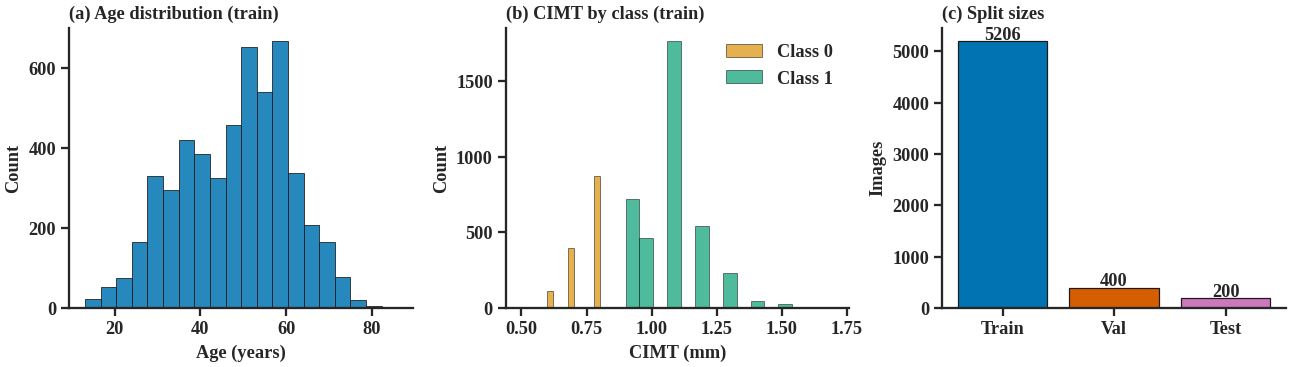

In [4]:
def get_patient_id(base_name):
    return re.sub(r'(_L|_R|_OD|_OS)$', '', base_name, flags=re.IGNORECASE)

df = pd.read_csv(CFG["csv_path"])
print(df.shape)
display(df.head())

df["patient"] = df["image_name"].apply(lambda x: get_patient_id(os.path.splitext(str(x))[0]))
train_df = df[df["group"] == 1].reset_index(drop=True)
val_df   = df[df["group"] == 2].reset_index(drop=True)
test_df  = df[df["group"] == 3].reset_index(drop=True)

p_tr, p_va, p_te = set(train_df["patient"]), set(val_df["patient"]), set(test_df["patient"])
assert len(p_tr & p_va) == 0 and len(p_tr & p_te) == 0 and len(p_va & p_te) == 0
print(f"patients train/val/test = {len(p_tr)}/{len(p_va)}/{len(p_te)} | overlap tv=0 tt=0 vt=0")
print(f"images train/val/test = {len(train_df)} {len(val_df)} {len(test_df)}")

AGE_COL = "True_age" if "True_age" in df.columns else "age"
SCALER = dict(
    age_mu = float(train_df[AGE_COL].mean()),
    age_sd = float(train_df[AGE_COL].std() + 1e-8),
    t_mu   = float(train_df["thickness"].mean()),
    t_sd   = float(train_df["thickness"].std() + 1e-8),
)
print(SCALER)
print("label counts (train):", train_df["label"].value_counts().to_dict())

def _summ(split_df, name):
    n_pat = split_df["patient"].nunique()
    n_img = len(split_df)
    age_m, age_s = split_df[AGE_COL].mean(), split_df[AGE_COL].std()
    g1 = int((split_df["gender"] == 1).sum())
    c1 = int((split_df["label"] == 1).sum())
    t_m, t_s = split_df["thickness"].mean(), split_df["thickness"].std()
    return {
        "Split": name, "Patients": n_pat, "Images": n_img,
        "Age, years (mean ± SD)": f"{age_m:.1f} ± {age_s:.1f}",
        "Gender 1, n (%)": f"{g1} ({100 * g1 / max(n_img,1):.1f}%)",
        "Class 1, n (%)": f"{c1} ({100 * c1 / max(n_img,1):.1f}%)",
        "CIMT, mm (mean ± SD)": f"{t_m:.2f} ± {t_s:.2f}",
    }

tab1 = pd.DataFrame([_summ(train_df, "Training"), _summ(val_df, "Validation"),
                     _summ(test_df, "Test"), _summ(df, "Total")])
show_table(tab1, "dataset_characteristics",
           "Characteristics of the fundus-image dataset and the patient-level train / validation / test split.",
           note="Both eyes of a patient are always in the same split (verified, no patient overlap). CIMT = carotid intima-media thickness. A/V masks come from the Fundus_A and V dataset.")

# ---------- Fig. 1 Dataset overview ----------
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].hist(train_df[AGE_COL], bins=20, color=PAL[0], alpha=0.85, edgecolor="k", linewidth=0.6)
axes[0].set_xlabel("Age (years)"); axes[0].set_ylabel("Count")
ttl(axes[0], "a", "Age distribution (train)")
for lab, col in [(0, PAL[1]), (1, PAL[2])]:
    sub = train_df[train_df["label"] == lab]["thickness"]
    axes[1].hist(sub, bins=15, alpha=0.7, color=col, label=CLASS_NAMES.get(lab, str(lab)), edgecolor="k", linewidth=0.5)
axes[1].set_xlabel("CIMT (mm)"); axes[1].set_ylabel("Count"); axes[1].legend(frameon=False)
ttl(axes[1], "b", "CIMT by class (train)")
sizes = [len(train_df), len(val_df), len(test_df)]
axes[2].bar(["Train", "Val", "Test"], sizes, color=[PAL[0], PAL[3], PAL[4]], edgecolor="k", linewidth=0.8)
axes[2].set_ylabel("Images")
for i, v in enumerate(sizes):
    axes[2].text(i, v + 30, str(v), ha="center", fontweight="bold", fontsize=FS)
ttl(axes[2], "c", "Split sizes")
plt.tight_layout()
save_fig(fig, "dataset_overview",
         "Dataset overview. (a) Age distribution in the training set. (b) CIMT distribution by disease class. (c) Number of images per split.")


## 5. Dataset and data loaders (vessel + A/V multi-class mask)
Supports `{base}_av.png` (0/1/2), `{base}_artery.png`+`{base}_vein.png`, or `artery/`+`vein/` subfolders.


In [5]:
def _load_av_mask(av_dir, base, size):
    """Return (H,W) int64 with 0=bg, 1=artery, 2=vein. None if not found."""
    if av_dir is None or not os.path.isdir(av_dir):
        return None
    candidates = [
        os.path.join(av_dir, base + "_av.png"),
        os.path.join(av_dir, base + "_AV.png"),
        os.path.join(av_dir, base + ".png"),
    ]
    for p in candidates:
        if os.path.isfile(p):
            m = np.asarray(Image.open(p).resize((size, size), Image.NEAREST))
            if m.ndim == 3:
                r, g, b = m[..., 0].astype(float), m[..., 1].astype(float), m[..., 2].astype(float)
                out = np.zeros(m.shape[:2], dtype=np.int64)
                out[(r > 120) & (r > g) & (r > b)] = 1   # red-ish -> artery
                out[(b > 120) & (b > r) & (b > g)] = 2   # blue-ish -> vein
                return out
            m = m.astype(np.float32)
            if m.max() > 2:
                m = m / 255.0
            out = np.zeros_like(m, dtype=np.int64)
            out[m > 0.6] = 2
            out[(m > 0.2) & (m <= 0.6)] = 1
            return out
    art_p = [os.path.join(av_dir, base + "_artery.png"),
             os.path.join(av_dir, "artery", base + ".png"),
             os.path.join(av_dir, "Artery", base + ".png")]
    vein_p = [os.path.join(av_dir, base + "_vein.png"),
              os.path.join(av_dir, "vein", base + ".png"),
              os.path.join(av_dir, "Vein", base + ".png")]
    art = next((p for p in art_p if os.path.isfile(p)), None)
    vein = next((p for p in vein_p if os.path.isfile(p)), None)
    if art is None and vein is None:
        return None
    out = np.zeros((size, size), dtype=np.int64)
    if art is not None:
        a = np.asarray(Image.open(art).convert("L").resize((size, size), Image.NEAREST)) > 127
        out[a] = 1
    if vein is not None:
        v = np.asarray(Image.open(vein).convert("L").resize((size, size), Image.NEAREST)) > 127
        out[v] = 2
    return out


class MTDataset(Dataset):
    def __init__(self, images_dir, masks_dir, av_masks_dir, df, img_size=512, augment=False, scaler=None):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.av_masks_dir = av_masks_dir
        self.df = df.reset_index(drop=True)
        self.img_size = img_size
        self.augment = augment
        self.sc = scaler if scaler is not None else SCALER
        n_av = 0
        for i in range(min(80, len(self.df))):
            base = os.path.splitext(str(self.df.iloc[i]["image_name"]))[0]
            if _load_av_mask(av_masks_dir, base, 64) is not None:
                n_av += 1
        print(f"  A/V mask probe (first 80): {n_av}/80 found")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        base = os.path.splitext(str(row["image_name"]))[0]
        s = self.img_size
        img_path = os.path.join(self.images_dir, base + ".png")
        mask_path = os.path.join(self.masks_dir, base + "_mask.png")
        img = Image.open(img_path).convert("RGB").resize((s, s), Image.BILINEAR)
        mask = Image.open(mask_path).convert("L").resize((s, s), Image.NEAREST)
        av = _load_av_mask(self.av_masks_dir, base, s)

        if self.augment:
            if random.random() < 0.5:
                img = img.transpose(Image.FLIP_LEFT_RIGHT)
                mask = mask.transpose(Image.FLIP_LEFT_RIGHT)
                if av is not None:
                    av = np.ascontiguousarray(np.fliplr(av))
            if random.random() < 0.5:
                a = random.uniform(-15, 15)
                img = img.rotate(a, resample=Image.BILINEAR)
                mask = mask.rotate(a, resample=Image.NEAREST)
                if av is not None:
                    av = np.asarray(Image.fromarray(av.astype(np.uint8)).rotate(a, resample=Image.NEAREST))

        img_np = np.asarray(img, dtype=np.float32) / 255.0
        mask_np = (np.asarray(mask, dtype=np.float32) / 255.0 > 0.5).astype(np.float32)
        if av is None:
            av_np = np.zeros((s, s), dtype=np.int64)
            has_av = 0.0
        else:
            av_np = av.astype(np.int64)
            has_av = 1.0

        if self.augment and random.random() < 0.3:
            rng = np.random.default_rng()
            img_np = np.clip(img_np + rng.normal(0, 0.02, img_np.shape), 0, 1).astype(np.float32)

        age = (float(row[AGE_COL]) - self.sc["age_mu"]) / self.sc["age_sd"]
        clin = torch.tensor([age, float(row["gender"])], dtype=torch.float32)
        thick = (float(row["thickness"]) - self.sc["t_mu"]) / self.sc["t_sd"]
        return (
            torch.from_numpy(img_np).permute(2, 0, 1).contiguous(),
            torch.from_numpy(mask_np).unsqueeze(0),
            torch.from_numpy(av_np).long(),
            torch.tensor(has_av, dtype=torch.float32),
            clin,
            torch.tensor(float(row["label"]), dtype=torch.float32),
            torch.tensor(thick, dtype=torch.float32),
        )


def _seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)


def make_ds_loader(df, augment, shuffle):
    ds = MTDataset(CFG["images_dir"], CFG["masks_dir"], CFG["av_masks_dir"],
                   df, CFG["img_size"], augment, SCALER)
    g = torch.Generator()
    g.manual_seed(CFG["seed"])
    dl = DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle, drop_last=augment,
                    num_workers=CFG["num_workers"], pin_memory=(device.type == "cuda"),
                    worker_init_fn=_seed_worker, generator=g)
    return ds, dl

train_ds, train_loader = make_ds_loader(train_df, True, True)
val_ds,   val_loader   = make_ds_loader(val_df, False, False)
test_ds,  test_loader  = make_ds_loader(test_df, False, False)
print(f"train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}")


  A/V mask probe (first 80): 80/80 found
  A/V mask probe (first 80): 80/80 found
  A/V mask probe (first 80): 80/80 found
train=5206 val=400 test=200


## 6. Model: Classic U-Net (multi-task + A/V head)

Standard U-Net encoder–decoder (Ronneberger et al.) with:
- 4 down / 4 up stages (base channels = 64)
- Skip connections (copy & crop / concat)
- Binary vessel head + 3-class A/V head
- Global average pool + clinical MLP → classification & regression heads


In [6]:
class DoubleConv(nn.Module):
    """(conv => BN => ReLU) * 2 — classic U-Net block"""
    def __init__(self, in_ch, out_ch, dropout_p=0.0):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        ]
        if dropout_p > 0:
            layers.append(nn.Dropout2d(dropout_p))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class Down(nn.Module):
    """MaxPool then DoubleConv"""
    def __init__(self, in_ch, out_ch, dropout_p=0.0):
        super().__init__()
        self.pool_conv = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_ch, out_ch, dropout_p)
        )

    def forward(self, x):
        return self.pool_conv(x)


class Up(nn.Module):
    """Upsample (bilinear or transposed conv) + concat skip + DoubleConv"""
    def __init__(self, in_ch, out_ch, bilinear=True, dropout_p=0.0):
        super().__init__()
        if bilinear:
            self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
            self.conv = DoubleConv(in_ch, out_ch, dropout_p)
        else:
            self.up = nn.ConvTranspose2d(in_ch // 2, in_ch // 2, 2, stride=2)
            self.conv = DoubleConv(in_ch, out_ch, dropout_p)

    def forward(self, x1, x2):
        x1 = self.up(x1)
        # pad if needed (odd sizes)
        diffY = x2.size(2) - x1.size(2)
        diffX = x2.size(3) - x1.size(3)
        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2,
                        diffY // 2, diffY - diffY // 2])
        x = torch.cat([x2, x1], dim=1)
        return self.conv(x)


class ClinicalMLP(nn.Module):
    def __init__(self, in_dim=2, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(inplace=True),
            nn.Linear(hidden, hidden), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.net(x)


class UNetMultiTask(nn.Module):
    """Classic U-Net with multi-task heads (vessel + A/V + cls + reg)."""
    def __init__(self, in_ch=3, base_ch=64, clinical_dim=2, clinical_hidden=32,
                 fc_dim=128, bilinear=True, use_clinical=True, n_av_classes=3):
        super().__init__()
        self.use_clinical = use_clinical
        self.clinical_hidden = clinical_hidden
        self.n_av_classes = n_av_classes
        self.bilinear = bilinear

        # Encoder
        self.inc   = DoubleConv(in_ch, base_ch, 0.1)          # 64
        self.down1 = Down(base_ch, base_ch * 2, 0.1)          # 128
        self.down2 = Down(base_ch * 2, base_ch * 4, 0.2)      # 256
        self.down3 = Down(base_ch * 4, base_ch * 8, 0.2)      # 512
        factor = 2 if bilinear else 1
        self.down4 = Down(base_ch * 8, base_ch * 16 // factor, 0.3)  # 1024 (or 512 if bilinear)

        # Decoder
        self.up1 = Up(base_ch * 16, base_ch * 8 // factor, bilinear, 0.2)
        self.up2 = Up(base_ch * 8,  base_ch * 4 // factor, bilinear, 0.2)
        self.up3 = Up(base_ch * 4,  base_ch * 2 // factor, bilinear, 0.1)
        self.up4 = Up(base_ch * 2,  base_ch, bilinear, 0.1)

        # Segmentation heads (from highest-resolution decoder features)
        self.seg_head = nn.Sequential(
            nn.Conv2d(base_ch, base_ch // 2, 1), nn.ReLU(inplace=True),
            nn.Conv2d(base_ch // 2, 1, 1))
        self.av_head = nn.Sequential(
            nn.Conv2d(base_ch, base_ch // 2, 1), nn.ReLU(inplace=True),
            nn.Conv2d(base_ch // 2, n_av_classes, 1))

        # Global features for classification / regression
        bottleneck_ch = base_ch * 16 // factor
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.clinical_mlp = ClinicalMLP(clinical_dim, clinical_hidden)
        self.shared_fc = nn.Sequential(
            nn.Linear(bottleneck_ch + clinical_hidden, fc_dim),
            nn.ReLU(inplace=True), nn.Dropout(0.3))
        self.cls_head = nn.Linear(fc_dim, 1)
        self.reg_head = nn.Linear(fc_dim, 1)

    def forward(self, x, clinical=None):
        # Encoder
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        # Decoder with skips
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        seg = self.seg_head(x)
        av  = self.av_head(x)

        cls_logit = reg_pred = None
        if clinical is not None:
            pooled = self.gap(x5).flatten(1)
            cf = (self.clinical_mlp(clinical) if self.use_clinical
                  else pooled.new_zeros(pooled.shape[0], self.clinical_hidden))
            h = self.shared_fc(torch.cat([pooled, cf], 1))
            cls_logit = self.cls_head(h).squeeze(1)
            reg_pred  = self.reg_head(h).squeeze(1)

        return dict(seg=seg, av=av, deep=[seg], cls=cls_logit, reg=reg_pred, att={})


model = UNetMultiTask(base_ch=CFG["base_ch"]).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {n_params:,}")
with torch.no_grad():
    model.eval()
    o = model(torch.randn(2, 3, min(CFG["img_size"], 128), min(CFG["img_size"], 128), device=device),
              torch.randn(2, 2, device=device))
print("seg:", tuple(o["seg"].shape), "| av:", tuple(o["av"].shape),
      "| cls:", tuple(o["cls"].shape), "| reg:", tuple(o["reg"].shape))


Total parameters: 13,466,758
seg: (2, 1, 128, 128) | av: (2, 3, 128, 128) | cls: (2,) | reg: (2,)


## 7. Architecture figure (Fig. 2)


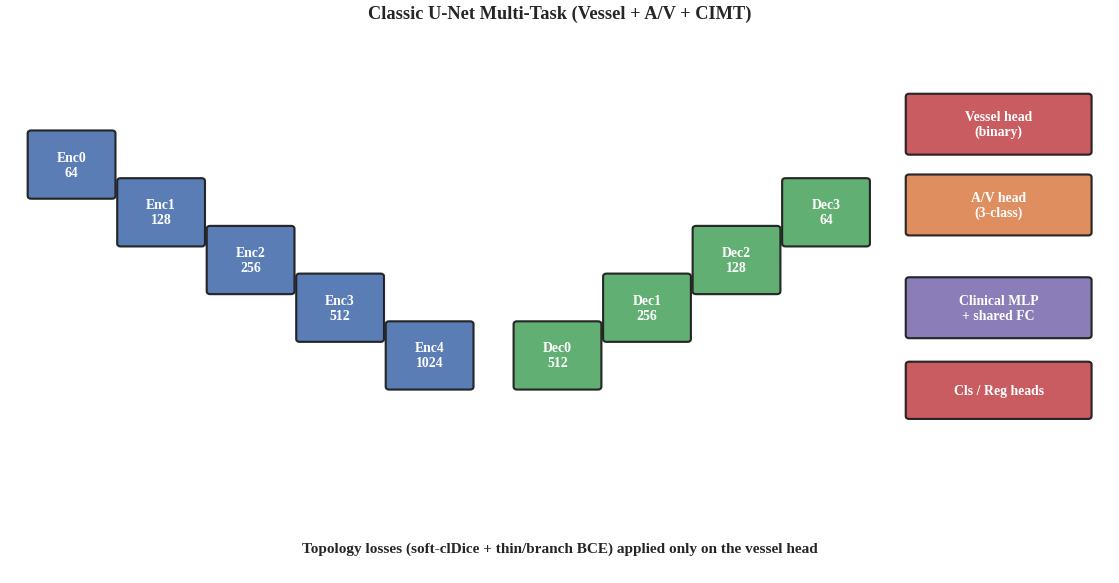

In [7]:
def draw_architecture():
    fig, ax = plt.subplots(figsize=(13, 6.5))
    ax.set_xlim(0, 13); ax.set_ylim(0, 7.5); ax.axis("off")
    colors = dict(enc="#4C72B0", dec="#55A868", head="#C44E52", clin="#8172B2", av="#DD8452")
    def box(x, y, w, h, txt, fc):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04",
                                    fc=fc, ec="k", lw=1.4, alpha=0.92))
        ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center",
                fontsize=9, fontweight="bold", color="white", fontfamily="serif")
    # Encoder (classic 64-128-256-512-1024)
    for i, ch in enumerate([64, 128, 256, 512, 1024]):
        box(0.3 + i * 1.05, 5.2 - i * 0.65, 0.95, 0.85, f"Enc{i}\n{ch}", colors["enc"])
    # Decoder
    for i, ch in enumerate([512, 256, 128, 64]):
        box(6.0 + i * 1.05, 2.6 + i * 0.65, 0.95, 0.85, f"Dec{i}\n{ch}", colors["dec"])
    box(10.6, 5.8, 2.1, 0.75, "Vessel head\n(binary)", colors["head"])
    box(10.6, 4.7, 2.1, 0.75, "A/V head\n(3-class)", colors["av"])
    box(10.6, 3.3, 2.1, 0.75, "Clinical MLP\n+ shared FC", colors["clin"])
    box(10.6, 2.2, 2.1, 0.7, "Cls / Reg heads", colors["head"])
    ax.text(6.5, 0.35,
            "Topology losses (soft-clDice + thin/branch BCE) applied only on the vessel head",
            ha="center", fontsize=10, fontweight="bold", fontfamily="serif")
    ax.set_title("Classic U-Net Multi-Task (Vessel + A/V + CIMT)",
                 fontweight="bold", fontfamily="serif", fontsize=FS)
    save_fig(fig, "architecture",
             "Network architecture. Shared classic U-Net encoder–decoder produces a binary vessel mask "
             "(Task 3, topology-aware) and a 3-class Artery/Vein/Background mask (Task 4). "
             "Global features + clinical variables feed the classification and regression heads.")

draw_architecture()


## 8. Parameter count


In [8]:
def component_params(m):
    parts = [
        ("Encoder (inc + downs)", sum(p.numel() for p in list(m.inc.parameters()) +
             list(m.down1.parameters()) + list(m.down2.parameters()) +
             list(m.down3.parameters()) + list(m.down4.parameters()))),
        ("Decoder (ups)", sum(p.numel() for p in list(m.up1.parameters()) +
             list(m.up2.parameters()) + list(m.up3.parameters()) + list(m.up4.parameters()))),
        ("Vessel head", sum(p.numel() for p in m.seg_head.parameters())),
        ("A/V head", sum(p.numel() for p in m.av_head.parameters())),
        ("Clinical + shared FC + cls/reg",
         sum(p.numel() for p in list(m.clinical_mlp.parameters()) +
             list(m.shared_fc.parameters()) + list(m.cls_head.parameters()) + list(m.reg_head.parameters()))),
    ]
    return pd.DataFrame(parts, columns=["Component", "Parameters"])

cp = component_params(model)
cp["Parameters (M)"] = (cp["Parameters"] / 1e6).round(4)
show_table(cp[["Component", "Parameters (M)"]], "model_components",
           "Parameter breakdown of the classic U-Net multi-task network.",
           align="left", precision=4)
print("Total parameters:", f"{n_params:,}")


Component,Parameters (M)
Encoder (inc + downs),9.4079
Decoder (ups),3.9834
Vessel head,0.0021
A/V head,0.0022
Clinical + shared FC + cls/reg,0.0712


Total parameters: 13,466,758


## 9. Loss (vessel topology + multi-class A/V) and metrics


In [9]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth
    def forward(self, logits, targets):
        p = torch.sigmoid(logits)
        inter = (p * targets).sum(dim=(1, 2, 3))
        union = p.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
        return (1 - (2 * inter + self.smooth) / (union + self.smooth)).mean()


class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma
    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        p = torch.sigmoid(logits)
        pt = p * targets + (1 - p) * (1 - targets)
        return (self.alpha * (1 - pt) ** self.gamma * bce).mean()


class SoftclDiceLoss(nn.Module):
    """Soft centreline Dice (topology-aware)."""
    def __init__(self, iters=10, smooth=1.0):
        super().__init__()
        self.iters, self.smooth = iters, smooth

    def soft_skeletonize(self, x):
        # iterative soft morphological erosion approximation
        for _ in range(self.iters):
            min_pool = -F.max_pool2d(-x, 3, stride=1, padding=1)
            x = x * (x == min_pool).float() + (1 - (x == min_pool).float()) * min_pool
        return x

    def forward(self, logits, targets):
        p = torch.sigmoid(logits)
        t = targets
        sp = self.soft_skeletonize(p)
        st = self.soft_skeletonize(t)
        tprec = (sp * t).sum(dim=(1, 2, 3)) / (sp.sum(dim=(1, 2, 3)) + 1e-8)
        tsens = (st * p).sum(dim=(1, 2, 3)) / (st.sum(dim=(1, 2, 3)) + 1e-8)
        cl = 2 * tprec * tsens / (tprec + tsens + 1e-8)
        return (1 - cl).mean()


class TopoWeightedBCE(nn.Module):
    """BCE weighted higher on thin vessels and branch points."""
    def __init__(self, iters=10, thin_boost=2.0, branch_boost=4.0):
        super().__init__()
        self.iters = iters
        self.tb, self.bb = thin_boost, branch_boost

    def weights(self, t):
        # approximate thin regions via local average
        avg = F.avg_pool2d(t, 5, stride=1, padding=2)
        thin = ((avg < 0.35) & (t > 0.5)).float()
        # rough branch: high local density of centreline
        sk = F.max_pool2d(t, 3, stride=1, padding=1) - F.avg_pool2d(t, 3, stride=1, padding=1)
        nb = F.avg_pool2d(sk, 3, stride=1, padding=1)
        branch = ((nb >= 0.15) & (sk > 0)).float()
        return torch.ones_like(t) + self.tb * thin + self.bb * branch

    def forward(self, logits, t):
        w = self.weights(t)
        return F.binary_cross_entropy_with_logits(logits, t, weight=w)


class MultiClassDiceLoss(nn.Module):
    def __init__(self, n_classes=3, smooth=1.0):
        super().__init__()
        self.n, self.s = n_classes, smooth
    def forward(self, logits, target):
        p = F.softmax(logits, dim=1)
        loss = 0.0
        for c in range(self.n):
            pc = p[:, c]
            tc = (target == c).float()
            inter = (pc * tc).sum(dim=(1, 2))
            union = pc.sum(dim=(1, 2)) + tc.sum(dim=(1, 2))
            loss = loss + (1 - (2 * inter + self.s) / (union + self.s)).mean()
        return loss / self.n


class MultiTaskLoss(nn.Module):
    def __init__(self, lam=0.5, w_seg=1.0, w_cls=1.0, w_reg=1.0, w_av=1.0,
                 pos_weight=None, cl_iters=10, thin_boost=2.0, branch_boost=4.0,
                 w_cl=0.5, w_wb=0.5):
        super().__init__()
        self.lam = lam
        self.w_seg, self.w_cls, self.w_reg, self.w_av = w_seg, w_cls, w_reg, w_av
        self.w_cl, self.w_wb = w_cl, w_wb
        self.dice = DiceLoss()
        self.focal = FocalLoss()
        self.cldice = SoftclDiceLoss(iters=cl_iters)
        self.wbce = TopoWeightedBCE(iters=cl_iters, thin_boost=thin_boost, branch_boost=branch_boost)
        self.av_dice = MultiClassDiceLoss(n_classes=3)
        self.ce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        self.mse = nn.MSELoss()
        self.ce_av = nn.CrossEntropyLoss(ignore_index=-1)

    def forward(self, out, masks, labels, thick, av_masks=None, has_av=None):
        seg_logits = out["seg"]
        l_dice = self.dice(seg_logits, masks)
        l_foc = self.focal(seg_logits, masks)
        l_cl = self.cldice(seg_logits, masks) if self.w_cl > 0 else seg_logits.new_zeros(())
        l_wb = self.wbce(seg_logits, masks) if self.w_wb > 0 else seg_logits.new_zeros(())
        l_seg = l_dice + self.lam * l_foc + self.w_cl * l_cl + self.w_wb * l_wb

        l_cls = self.ce(out["cls"], labels) if out["cls"] is not None else seg_logits.new_zeros(())
        l_reg = self.mse(out["reg"], thick) if out["reg"] is not None else seg_logits.new_zeros(())

        l_av = seg_logits.new_zeros(())
        if av_masks is not None and out.get("av") is not None and has_av is not None:
            valid = has_av > 0.5
            if valid.any():
                av_logits = out["av"][valid]
                av_tgt = av_masks[valid]
                l_av = self.av_dice(av_logits, av_tgt) + self.ce_av(av_logits, av_tgt)

        total = (self.w_seg * l_seg + self.w_cls * l_cls + self.w_reg * l_reg + self.w_av * l_av)
        return total, dict(
            seg=float(l_seg.detach()), cls=float(l_cls.detach()) if torch.is_tensor(l_cls) else float(l_cls),
            reg=float(l_reg.detach()) if torch.is_tensor(l_reg) else float(l_reg),
            av=float(l_av.detach()) if torch.is_tensor(l_av) else float(l_av))


pos = (train_df["label"] == 1).sum()
neg = (train_df["label"] == 0).sum()
pos_weight = torch.tensor([neg / max(pos, 1)], device=device, dtype=torch.float32)
criterion = MultiTaskLoss(
    CFG["lam"], CFG["w_seg"], CFG["w_cls"], CFG["w_reg"], CFG["w_av"],
    pos_weight=pos_weight, cl_iters=CFG["cl_iters"],
    thin_boost=CFG["thin_boost"], branch_boost=CFG["branch_boost"],
    w_cl=CFG["w_cl"], w_wb=CFG["w_wb"])
print("Loss ready (vessel topology + A/V multi-class).")


Loss ready (vessel topology + A/V multi-class).


In [10]:
def per_image_seg(logits, masks):
    p = (torch.sigmoid(logits) > 0.5).float()
    t = masks
    e = 1e-7
    tp = (p * t).sum(dim=(1, 2, 3))
    fp = (p * (1 - t)).sum(dim=(1, 2, 3))
    fn = ((1 - p) * t).sum(dim=(1, 2, 3))
    tn = ((1 - p) * (1 - t)).sum(dim=(1, 2, 3))
    d = dict(
        Dice=(2 * tp + e) / (2 * tp + fp + fn + e),
        IoU=(tp + e) / (tp + fp + fn + e),
        ACC=(tp + tn) / (tp + tn + fp + fn + e),
        SE=tp / (tp + fn + e),
        SP=tn / (tn + fp + e),
    )
    return {k: v.detach().cpu().numpy() for k, v in d.items()}


def per_image_av(logits, av_masks, has_av):
    pred = logits.argmax(1)
    dices = []
    for b in range(logits.size(0)):
        if has_av[b] < 0.5:
            dices.append(np.nan)
            continue
        ds = []
        for c in (1, 2):
            p = (pred[b] == c).float()
            t = (av_masks[b] == c).float()
            inter = (p * t).sum()
            union = p.sum() + t.sum()
            ds.append(((2 * inter + 1e-7) / (union + 1e-7)).item())
        dices.append(float(np.mean(ds)))
    return np.asarray(dices, dtype=np.float32)


@torch.no_grad()
def evaluate(model, loader, criterion=None, collect_pixels=False, pix_per_img=2000):
    model.eval()
    seg = {k: [] for k in ["Dice", "IoU", "ACC", "SE", "SP"]}
    av_dice, cls_p, cls_t, reg_p, reg_t = [], [], [], [], []
    pix_p, pix_t = [], []
    tot, n = 0.0, 0
    for batch in loader:
        imgs, masks, av_masks, has_av, clin, labels, thick = batch
        imgs = imgs.to(device)
        masks = masks.to(device)
        av_masks = av_masks.to(device)
        has_av = has_av.to(device)
        clin = clin.to(device)
        labels = labels.to(device)
        thick = thick.to(device)
        with autocast_ctx():
            out = model(imgs, clin)
        if criterion is not None and out["cls"] is not None:
            loss, _ = criterion(out, masks, labels, thick, av_masks, has_av)
            tot += loss.item() * imgs.size(0)
        n += imgs.size(0)
        for k, v in per_image_seg(out["seg"], masks).items():
            seg[k].append(v)
        av_dice.append(per_image_av(out["av"], av_masks, has_av))
        if out["cls"] is not None:
            cls_p.append(torch.sigmoid(out["cls"].float()).cpu().numpy())
            cls_t.append(labels.cpu().numpy())
            reg_p.append(out["reg"].float().cpu().numpy() * SCALER["t_sd"] + SCALER["t_mu"])
            reg_t.append(thick.cpu().numpy() * SCALER["t_sd"] + SCALER["t_mu"])
        if collect_pixels:
            pr = torch.sigmoid(out["seg"].float()).flatten(1)
            tg = masks.flatten(1)
            idx = torch.randint(0, pr.shape[1], (pix_per_img,), device=pr.device)
            pix_p.append(pr[:, idx].cpu().numpy().ravel())
            pix_t.append(tg[:, idx].cpu().numpy().ravel())
    res = dict(
        seg={k: np.concatenate(v) for k, v in seg.items()},
        av_dice=np.concatenate(av_dice),
        loss=tot / max(n, 1),
    )
    if cls_p:
        res.update(
            cls_prob=np.concatenate(cls_p), cls_true=np.concatenate(cls_t),
            reg_pred=np.concatenate(reg_p), reg_true=np.concatenate(reg_t))
    if collect_pixels:
        res.update(pix_prob=np.concatenate(pix_p), pix_true=np.concatenate(pix_t))
    return res


def summarize(res):
    m = {f"seg_{k}": float(v.mean()) for k, v in res["seg"].items()}
    av = res["av_dice"]
    m["av_Dice"] = float(np.nanmean(av)) if np.any(~np.isnan(av)) else float("nan")
    if "cls_prob" in res:
        y, p = res["cls_true"], res["cls_prob"]
        m["cls_ACC"] = float(accuracy_score(y, p > 0.5))
        m["cls_AUC"] = float(roc_auc_score(y, p)) if len(np.unique(y)) > 1 else float("nan")
        m["reg_MAE"] = float(mean_absolute_error(res["reg_true"], res["reg_pred"]))
        m["reg_RMSE"] = float(mean_squared_error(res["reg_true"], res["reg_pred"]) ** 0.5)
        m["reg_R2"] = float(r2_score(res["reg_true"], res["reg_pred"]))
    return m


## 10. Implementation details (Table 2)


In [11]:
impl = [
    ("Framework", f"PyTorch {torch.__version__}"),
    ("Hardware", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"),
    ("Input size", f'{CFG["img_size"]}×{CFG["img_size"]}'),
    ("Batch size / epochs", f'{CFG["batch_size"]} / {CFG["epochs"]}'),
    ("Optimizer", f'Adam (lr={CFG["lr"]}, wd={CFG["weight_decay"]})'),
    ("Architecture", "Classic U-Net (no DCN / SPP / Attention Gates)"),
    ("Loss – vessel", "Dice + λ·Focal + soft-clDice + thin/branch-weighted BCE"),
    ("Loss – A/V", "Multi-class Dice + Cross-Entropy (3 classes)"),
    ("Loss – classification", "BCEWithLogits (pos_weight from train)"),
    ("Loss – regression", "MSE on z-scored CIMT"),
    ("Topology (vessel only)", f'w_cl={CFG["w_cl"]}, w_wb={CFG["w_wb"]}, cl_iters={CFG["cl_iters"]}'),
    ("Task weights", f'seg={CFG["w_seg"]}, av={CFG["w_av"]}, cls={CFG["w_cls"]}, reg={CFG["w_reg"]}'),
    ("A/V mask source", os.path.basename(CFG["av_masks_dir"]) if CFG["av_masks_dir"] else "–"),
    ("Patient-level split", "CSV group column (verified zero overlap)"),
    ("Font / figure style", "Times New Roman 12 pt bold, 600 dpi PNG+PDF+TIFF"),
]
show_table(pd.DataFrame(impl, columns=["Item", "Setting"]), "implementation_details",
           "Implementation details of the multi-task classic U-Net (Tasks 1–4).",
           align="left", precision=0)


Item,Setting
Framework,PyTorch 2.11.0+cu130
Hardware,Tesla T4
Input size,512×512
Batch size / epochs,8 / 30
Optimizer,"Adam (lr=0.0001, wd=1e-05)"
Architecture,Classic U-Net (no DCN / SPP / Attention Gates)
Loss – vessel,Dice + λ·Focal + soft-clDice + thin/branch-weighted BCE
Loss – A/V,Multi-class Dice + Cross-Entropy (3 classes)
Loss – classification,BCEWithLogits (pos_weight from train)
Loss – regression,MSE on z-scored CIMT


## 11. Training


In [12]:
def train_one_epoch(model, loader, optimizer, grad_scaler):
    model.train()
    tot = seg_t = cls_t = reg_t = av_t = 0.0
    for batch in loader:
        imgs, masks, av_masks, has_av, clin, labels, thick = batch
        imgs = imgs.to(device)
        masks = masks.to(device)
        av_masks = av_masks.to(device)
        has_av = has_av.to(device)
        clin = clin.to(device)
        labels = labels.to(device)
        thick = thick.to(device)
        optimizer.zero_grad(set_to_none=True)
        with autocast_ctx():
            out = model(imgs, clin)
            loss, parts = criterion(out, masks, labels, thick, av_masks, has_av)
        grad_scaler.scale(loss).backward()
        grad_scaler.step(optimizer)
        grad_scaler.update()
        b = imgs.size(0)
        tot += loss.item() * b
        seg_t += parts["seg"] * b
        cls_t += parts["cls"] * b
        reg_t += parts["reg"] * b
        av_t += parts["av"] * b
    n = len(loader.dataset) if not getattr(loader, "drop_last", False) else len(loader) * loader.batch_size
    return tot / n, seg_t / n, cls_t / n, reg_t / n, av_t / n


def fit(model, epochs, ckpt_best, verbose=True, score_w=(1.0, 1.0, 1.0, 1.0)):
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    try:
        grad_scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        grad_scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    best_score, best_epoch, hist = -1e9, 0, []
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_seg, tr_cls, tr_reg, tr_av = train_one_epoch(model, train_loader, optimizer, grad_scaler)
        vres = evaluate(model, val_loader, criterion)
        vm = summarize(vres)
        scheduler.step(vres["loss"])
        av_score = vm.get("av_Dice", 0.0)
        if isinstance(av_score, float) and np.isnan(av_score):
            av_score = 0.0
        score = (score_w[0] * vm["seg_Dice"] + score_w[1] * vm.get("cls_ACC", 0.0) +
                 score_w[2] * vm.get("reg_R2", 0.0) + score_w[3] * av_score)
        dt = time.time() - t0
        hist.append(dict(
            epoch=epoch, train_loss=tr_loss, train_seg=tr_seg, train_cls=tr_cls,
            train_reg=tr_reg, train_av=tr_av, val_loss=vres["loss"],
            lr=optimizer.param_groups[0]["lr"], time_s=dt, **vm))
        flag = ""
        if score > best_score:
            best_score, best_epoch = score, epoch
            torch.save(model.state_dict(), ckpt_best)
            flag = "  <- best"
        if verbose:
            avs = f'{vm.get("av_Dice", float("nan")):.4f}' if not np.isnan(vm.get("av_Dice", np.nan)) else "n/a"
            print(f"Ep {epoch:03d}/{epochs} ({dt:.0f}s) loss {tr_loss:.3f}/{vres['loss']:.3f} | "
                  f"Dice {vm['seg_Dice']:.4f} | A/V {avs} | cls {vm.get('cls_ACC', 0):.3f} | "
                  f"MAE {vm.get('reg_MAE', 0):.4f} R2 {vm.get('reg_R2', 0):.3f}{flag}")
    torch.save(model.state_dict(), ckpt_best.replace("_best", "_last"))
    return pd.DataFrame(hist), best_epoch


if RUN_TRAINING:
    best_ckpt = os.path.join(CFG["out_dir"], "unet_multitask_av_best.pth")
    hist_df, best_epoch = fit(model, CFG["epochs"], best_ckpt)
    hist_df.to_csv(os.path.join(CFG["out_dir"], "unet_training_history.csv"), index=False)
else:
    best_ckpt = os.path.join(CKPT_DIR, "unet_multitask_av_best.pth")
    if not os.path.isfile(best_ckpt):
        best_ckpt = os.path.join(CKPT_DIR, "unet_multitask_best.pth")
    hist_path = os.path.join(CKPT_DIR, "unet_training_history.csv")
    if os.path.isfile(hist_path):
        hist_df = pd.read_csv(hist_path)
        best_epoch = int(hist_df["epoch"].iloc[hist_df["seg_Dice"].values.argmax()]) if "seg_Dice" in hist_df.columns else int(hist_df["epoch"].iloc[-1])
    else:
        hist_df = pd.DataFrame([{"epoch": 1, "seg_Dice": 0.0, "time_s": 0.0}])
        best_epoch = 1
    print("RUN_TRAINING = False -> using", best_ckpt)


Ep 001/30 (891s) loss 3.412/nan | Dice 0.8484 | A/V 0.4479 | cls 0.720 | MAE 0.1578 R2 0.220  <- best
Ep 002/30 (572s) loss 2.303/nan | Dice 0.8873 | A/V 0.6672 | cls 0.790 | MAE 0.1384 R2 0.360  <- best
Ep 003/30 (574s) loss 2.093/nan | Dice 0.9026 | A/V 0.7707 | cls 0.780 | MAE 0.1442 R2 0.311  <- best
Ep 004/30 (573s) loss 1.988/nan | Dice 0.9109 | A/V 0.8144 | cls 0.787 | MAE 0.1363 R2 0.371  <- best
Ep 005/30 (573s) loss 1.932/nan | Dice 0.9171 | A/V 0.8440 | cls 0.777 | MAE 0.1396 R2 0.347  <- best
Ep 006/30 (570s) loss 1.899/nan | Dice 0.9193 | A/V 0.8641 | cls 0.775 | MAE 0.1378 R2 0.349  <- best
Ep 007/30 (571s) loss 1.865/nan | Dice 0.9205 | A/V 0.8788 | cls 0.780 | MAE 0.1395 R2 0.360  <- best
Ep 008/30 (568s) loss 1.856/nan | Dice 0.9212 | A/V 0.8835 | cls 0.780 | MAE 0.1381 R2 0.365  <- best
Ep 009/30 (569s) loss 1.846/nan | Dice 0.9228 | A/V 0.8871 | cls 0.782 | MAE 0.1407 R2 0.348
Ep 010/30 (570s) loss 1.842/nan | Dice 0.9227 | A/V 0.8907 | cls 0.780 | MAE 0.1381 R2 0.35

## 12. Model size, training summary (Table 3) and training curves (Fig. 6)


Item,Value
Parameters (M),13.467
Best epoch,11
Val Dice (vessel),0.9238
Val A/V Dice (mean art+vein),0.8960
Val Cls ACC,0.7900
Val Reg R²,0.3841
Mean epoch time (s),577.8


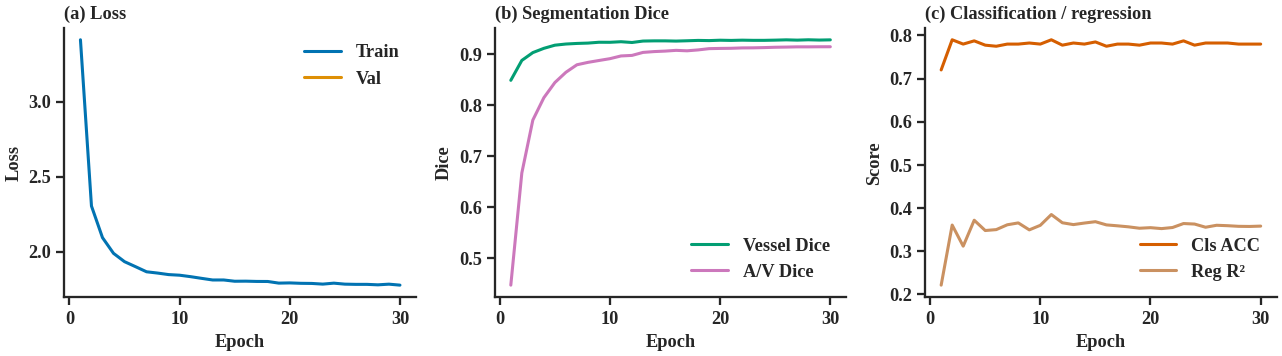

In [13]:
bh = hist_df[hist_df["epoch"] == best_epoch].iloc[0] if "epoch" in hist_df.columns else hist_df.iloc[-1]
has_t = "time_s" in hist_df.columns and hist_df["time_s"].notna().any()
tab3 = pd.DataFrame([
    ("Parameters (M)", f"{n_params / 1e6:.3f}"),
    ("Best epoch", int(bh.get("epoch", best_epoch))),
    ("Val Dice (vessel)", f'{bh.get("seg_Dice", float("nan")):.4f}'),
    ("Val A/V Dice (mean art+vein)", f'{bh.get("av_Dice", float("nan")):.4f}'),
    ("Val Cls ACC", f'{bh.get("cls_ACC", float("nan")):.4f}'),
    ("Val Reg R²", f'{bh.get("reg_R2", float("nan")):.4f}'),
    ("Mean epoch time (s)", f'{hist_df["time_s"].mean():.1f}' if has_t else "–"),
], columns=["Item", "Value"])
show_table(tab3, "model_complexity",
           "Model size, best validation metrics and training summary (Tasks 1–4).",
           align="left", precision=0)

# Training curves
if len(hist_df) > 1 and "train_loss" in hist_df.columns:
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    ep = hist_df["epoch"].values
    axes[0].plot(ep, hist_df["train_loss"], label="Train", color=PAL[0])
    if "val_loss" in hist_df.columns:
        axes[0].plot(ep, hist_df["val_loss"], label="Val", color=PAL[1])
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend(frameon=False)
    ttl(axes[0], "a", "Loss")
    if "seg_Dice" in hist_df.columns:
        axes[1].plot(ep, hist_df["seg_Dice"], color=PAL[2], label="Vessel Dice")
        if "av_Dice" in hist_df.columns:
            axes[1].plot(ep, hist_df["av_Dice"], color=PAL[4], label="A/V Dice")
        axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Dice"); axes[1].legend(frameon=False)
        ttl(axes[1], "b", "Segmentation Dice")
    if "cls_ACC" in hist_df.columns:
        axes[2].plot(ep, hist_df["cls_ACC"], color=PAL[3], label="Cls ACC")
        if "reg_R2" in hist_df.columns:
            axes[2].plot(ep, hist_df["reg_R2"], color=PAL[5], label="Reg R²")
        axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Score"); axes[2].legend(frameon=False)
        ttl(axes[2], "c", "Classification / regression")
    plt.tight_layout()
    save_fig(fig, "training_curves",
             "Training curves of the classic U-Net multi-task model. (a) Train and validation loss. "
             "(b) Vessel Dice and A/V Dice on the validation set. (c) Classification accuracy and regression R².")


## 13. Test evaluation with patient-level bootstrap 95 % CI (Table 4) and performance figure (Fig. 3)


Test metrics: {'seg_Dice': 0.9236617088317871, 'seg_IoU': 0.8585102558135986, 'seg_ACC': 0.985159695148468, 'seg_SE': 0.9339642524719238, 'seg_SP': 0.9904659986495972, 'av_Dice': 0.8958603143692017, 'cls_ACC': 0.87, 'cls_AUC': 0.9463, 'reg_MAE': 0.10779088735580444, 'reg_RMSE': 0.13845326425381557, 'reg_R2': 0.47915154695510864}


Metric,Value (95 % CI where applicable)
Vessel Dice,0.9237 (0.9208–0.9261)
Vessel IoU,0.8585 (0.8544–0.8629)
Vessel Sensitivity,0.9340 (0.9300–0.9383)
Vessel Specificity,0.9905 (0.9902–0.9908)
A/V Dice (artery+vein),0.8959 (0.8914–0.9003)
Cls Accuracy,0.8700
Cls AUC,0.9463
Cls F1,0.8762
Reg MAE (mm),0.1078
Reg RMSE (mm),0.1385


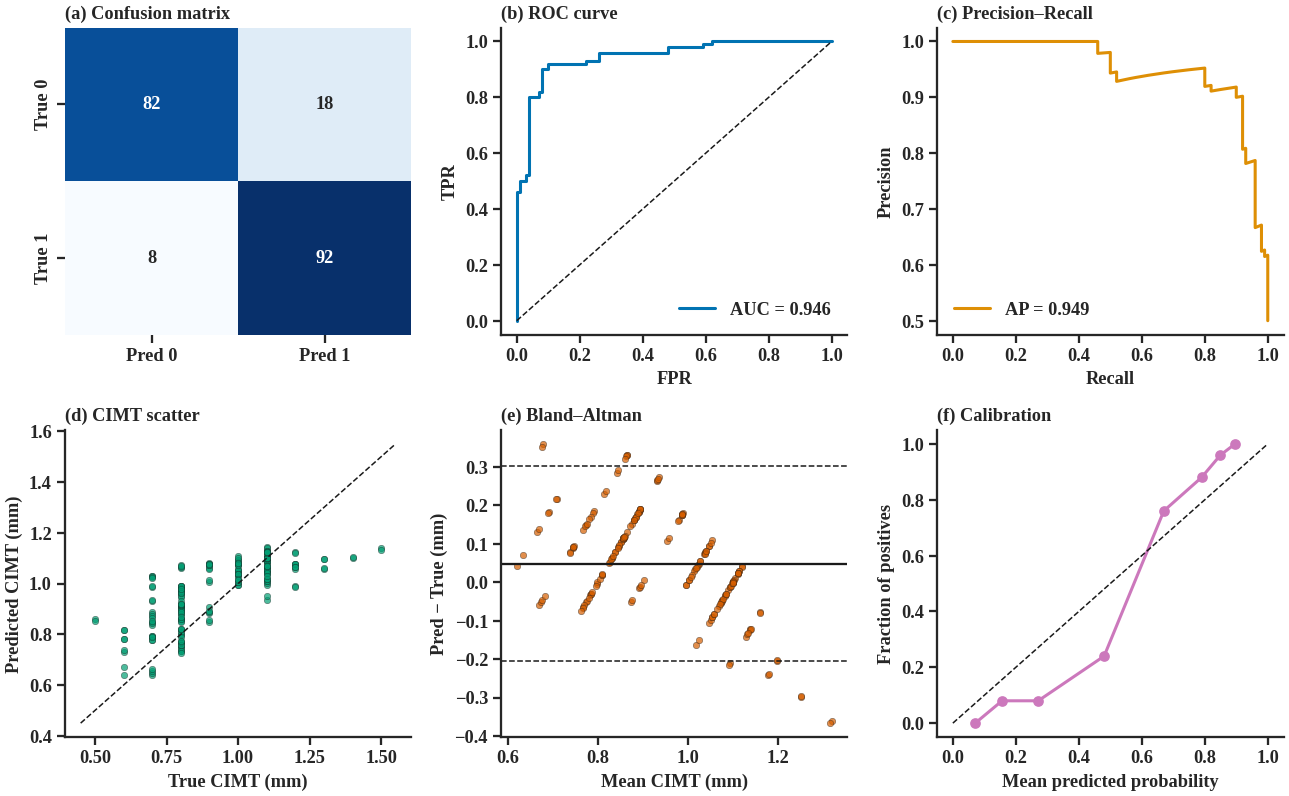

In [14]:
model.load_state_dict(torch.load(best_ckpt, map_location=device))
res = evaluate(model, test_loader, criterion, collect_pixels=True)
tm = summarize(res)
print("Test metrics:", tm)

rng = np.random.default_rng(42)
pids = test_df["patient"].values
unique_p = np.unique(pids)

def boot_ci(metric_arr, n_boot=500):
    per_pat = []
    for p in unique_p:
        idx = np.where(pids == p)[0]
        per_pat.append(np.nanmean(metric_arr[idx]))
    per_pat = np.asarray(per_pat, dtype=float)
    boots = [np.nanmean(rng.choice(per_pat, size=len(per_pat), replace=True)) for _ in range(n_boot)]
    return float(np.nanmean(per_pat)), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))

rows = []
for name, arr in [
    ("Vessel Dice", res["seg"]["Dice"]),
    ("Vessel IoU", res["seg"]["IoU"]),
    ("Vessel Sensitivity", res["seg"]["SE"]),
    ("Vessel Specificity", res["seg"]["SP"]),
    ("A/V Dice (artery+vein)", res["av_dice"]),
]:
    m, lo, hi = boot_ci(arr)
    rows.append((name, fmt_ci(m, lo, hi)))
if "cls_prob" in res:
    y, p = res["cls_true"], res["cls_prob"]
    rows.append(("Cls Accuracy", f"{accuracy_score(y, p > 0.5):.4f}"))
    rows.append(("Cls AUC", f"{roc_auc_score(y, p):.4f}"))
    rows.append(("Cls F1", f"{f1_score(y, p > 0.5):.4f}"))
    rows.append(("Reg MAE (mm)", f"{mean_absolute_error(res['reg_true'], res['reg_pred']):.4f}"))
    rows.append(("Reg RMSE (mm)", f"{mean_squared_error(res['reg_true'], res['reg_pred'])**0.5:.4f}"))
    rows.append(("Reg R²", f"{r2_score(res['reg_true'], res['reg_pred']):.4f}"))

show_table(pd.DataFrame(rows, columns=["Metric", "Value (95 % CI where applicable)"]),
           "main_test_results",
           "Main test-set results of the classic U-Net multi-task model (Tasks 1–4). "
           "Vessel and A/V metrics use patient-level bootstrap 95 % CI.",
           align="left")

# ---------- Fig. 3 Performance panel ----------
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
if "cls_prob" in res:
    y, p = res["cls_true"], res["cls_prob"]
    cm = confusion_matrix(y, p > 0.5)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0, 0],
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"],
                cbar=False, annot_kws={"size": FS, "weight": "bold"})
    ttl(axes[0, 0], "a", "Confusion matrix")
    fpr, tpr, _ = roc_curve(y, p)
    axes[0, 1].plot(fpr, tpr, color=PAL[0], lw=2, label=f"AUC = {roc_auc_score(y, p):.3f}")
    axes[0, 1].plot([0, 1], [0, 1], "k--", lw=1)
    axes[0, 1].set_xlabel("FPR"); axes[0, 1].set_ylabel("TPR")
    axes[0, 1].legend(frameon=False); ttl(axes[0, 1], "b", "ROC curve")
    prec, rec, _ = precision_recall_curve(y, p)
    axes[0, 2].plot(rec, prec, color=PAL[1], lw=2, label=f"AP = {average_precision_score(y, p):.3f}")
    axes[0, 2].set_xlabel("Recall"); axes[0, 2].set_ylabel("Precision")
    axes[0, 2].legend(frameon=False); ttl(axes[0, 2], "c", "Precision–Recall")
    axes[1, 0].scatter(res["reg_true"], res["reg_pred"], s=18, alpha=0.7, color=PAL[2], edgecolors="k", linewidths=0.3)
    lims = [min(res["reg_true"].min(), res["reg_pred"].min()) - 0.05,
            max(res["reg_true"].max(), res["reg_pred"].max()) + 0.05]
    axes[1, 0].plot(lims, lims, "k--", lw=1)
    axes[1, 0].set_xlabel("True CIMT (mm)"); axes[1, 0].set_ylabel("Predicted CIMT (mm)")
    ttl(axes[1, 0], "d", "CIMT scatter")
    mean_ba = (res["reg_true"] + res["reg_pred"]) / 2
    diff_ba = res["reg_pred"] - res["reg_true"]
    md, sd = diff_ba.mean(), diff_ba.std()
    axes[1, 1].scatter(mean_ba, diff_ba, s=18, alpha=0.7, color=PAL[3], edgecolors="k", linewidths=0.3)
    axes[1, 1].axhline(md, color="k", lw=1.5)
    axes[1, 1].axhline(md + 1.96 * sd, color="k", ls="--", lw=1)
    axes[1, 1].axhline(md - 1.96 * sd, color="k", ls="--", lw=1)
    axes[1, 1].set_xlabel("Mean CIMT (mm)"); axes[1, 1].set_ylabel("Pred − True (mm)")
    ttl(axes[1, 1], "e", "Bland–Altman")
    try:
        frac_pos, mean_pred = calibration_curve(y, p, n_bins=8, strategy="quantile")
        axes[1, 2].plot(mean_pred, frac_pos, "o-", color=PAL[4], lw=2)
        axes[1, 2].plot([0, 1], [0, 1], "k--", lw=1)
        axes[1, 2].set_xlabel("Mean predicted probability"); axes[1, 2].set_ylabel("Fraction of positives")
        ttl(axes[1, 2], "f", "Calibration")
    except Exception:
        axes[1, 2].axis("off")
else:
    for ax in axes.ravel():
        ax.axis("off")
plt.tight_layout()
save_fig(fig, "test_performance",
         "Test-set performance. (a) Classification confusion matrix. (b) ROC curve. (c) Precision–Recall curve. "
         "(d) CIMT regression scatter. (e) Bland–Altman plot. (f) Calibration curve.")


## 14. Subgroup analysis (Table 5)


In [15]:
with safe("subgroup analysis"):
    age_y = test_df[AGE_COL].values.astype(float)
    gend = test_df["gender"].values
    age_med = np.median(age_y)
    rows = []
    for name, mask in [
        ("All", np.ones(len(test_df), dtype=bool)),
        (f"Age ≤ {age_med:.0f}", age_y <= age_med),
        (f"Age > {age_med:.0f}", age_y > age_med),
        (GENDER_NAMES.get(0, "Gender 0"), gend == 0),
        (GENDER_NAMES.get(1, "Gender 1"), gend == 1),
    ]:
        if mask.sum() < 5:
            continue
        d = float(np.nanmean(res["seg"]["Dice"][mask]))
        av = float(np.nanmean(res["av_dice"][mask]))
        if "cls_prob" in res:
            y_s, p_s = res["cls_true"][mask], res["cls_prob"][mask]
            acc = float(accuracy_score(y_s, p_s > 0.5)) if len(y_s) else float("nan")
            auc = float(roc_auc_score(y_s, p_s)) if len(np.unique(y_s)) > 1 else float("nan")
            mae = float(mean_absolute_error(res["reg_true"][mask], res["reg_pred"][mask]))
        else:
            acc = auc = mae = float("nan")
        rows.append({"Subgroup": name, "N": int(mask.sum()),
                     "Vessel Dice": d, "A/V Dice": av,
                     "Cls ACC": acc, "Cls AUC": auc, "MAE (mm)": mae})
    tab5 = pd.DataFrame(rows)
    show_table(tab5, "subgroup_analysis",
               "Subgroup analysis on the test set (vessel Dice, A/V Dice, classification and regression).",
               precision=4)
    Q1_FLAGS["subgroup analysis"] = True


Subgroup,N,Vessel Dice,A/V Dice,Cls ACC,Cls AUC,MAE (mm)
All,200,0.9237,0.8959,0.8700,0.9463,0.1078
Age ≤ 48,100,0.9248,0.8943,0.8400,0.7860,0.1066
Age > 48,100,0.9225,0.8974,0.9000,0.8258,0.1090
Gender 0,74,0.9232,0.8977,0.8649,0.9010,0.1145
Gender 1,126,0.9239,0.8948,0.8730,0.9566,0.1038


## 15. Qualitative results – vessel + artery/vein (Fig. 4)


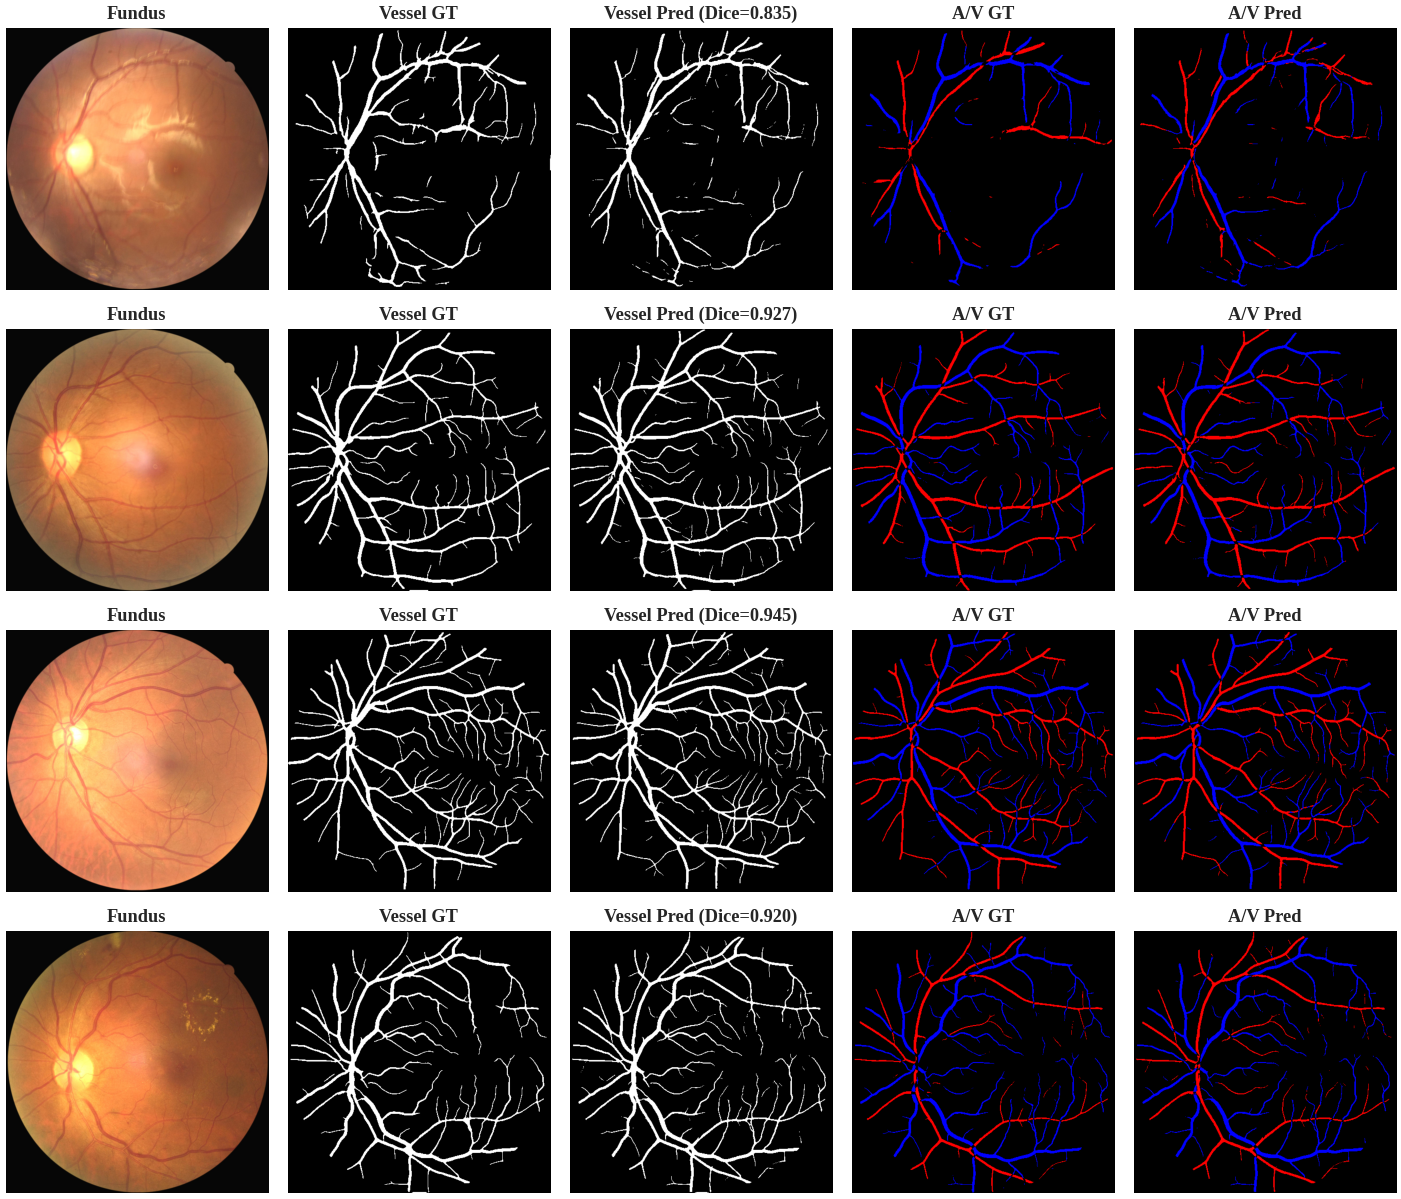

In [16]:
@torch.no_grad()
def show_qualitative(n=4):
    model.eval()
    dice = res["seg"]["Dice"]
    order = np.argsort(dice)
    idxs = [order[0], order[len(order)//2], order[-1]]
    if len(order) > 3:
        idxs.append(order[len(order)//4])
    idxs = idxs[:n]

    fig, axes = plt.subplots(n, 5, figsize=(13, 2.8 * n))
    if n == 1:
        axes = axes[None, :]
    for row, ii in enumerate(idxs):
        sample = test_ds[ii]
        img_t, mask_t, av_t, has_av_t, clin_t, _, _ = sample
        img_b = img_t.unsqueeze(0).to(device)
        clin_b = clin_t.unsqueeze(0).to(device)
        out = model(img_b, clin_b)
        seg_p = torch.sigmoid(out["seg"])[0, 0].cpu().numpy()
        av_p = out["av"][0].argmax(0).cpu().numpy()
        img_np = img_t.permute(1, 2, 0).numpy()
        mask_np = mask_t[0].numpy()
        av_np = av_t.numpy()

        def colour_av(m):
            rgb = np.zeros((*m.shape, 3), dtype=np.float32)
            rgb[m == 1, 0] = 1.0
            rgb[m == 2, 2] = 1.0
            return rgb

        axes[row, 0].imshow(np.clip(img_np, 0, 1)); axes[row, 0].set_title("Fundus", fontweight="bold"); axes[row, 0].axis("off")
        axes[row, 1].imshow(mask_np, cmap="gray"); axes[row, 1].set_title("Vessel GT", fontweight="bold"); axes[row, 1].axis("off")
        axes[row, 2].imshow(seg_p > 0.5, cmap="gray"); axes[row, 2].set_title(f"Vessel Pred (Dice={dice[ii]:.3f})", fontweight="bold"); axes[row, 2].axis("off")
        axes[row, 3].imshow(colour_av(av_np)); axes[row, 3].set_title("A/V GT", fontweight="bold"); axes[row, 3].axis("off")
        axes[row, 4].imshow(colour_av(av_p)); axes[row, 4].set_title("A/V Pred", fontweight="bold"); axes[row, 4].axis("off")
    plt.tight_layout()
    save_fig(fig, "qualitative_results",
             "Qualitative examples on the test set (worst / median / best vessel Dice). "
             "Columns: fundus, vessel GT, vessel prediction, A/V GT (red = artery, blue = vein), A/V prediction.")

show_qualitative(4)


## 16. Topology / thin-vessel / A/V metrics (Table 6, Fig. 5)


Metric,Value
Vessel Dice (test),0.9237
Vessel IoU (test),0.8585
"clDice (approx, n=40)",0.8496
Thin-vessel centreline recall (approx),0.8140
A/V mean Dice (art+vein),0.8959
Artery Dice (subset),0.8815
Vein Dice (subset),0.9132


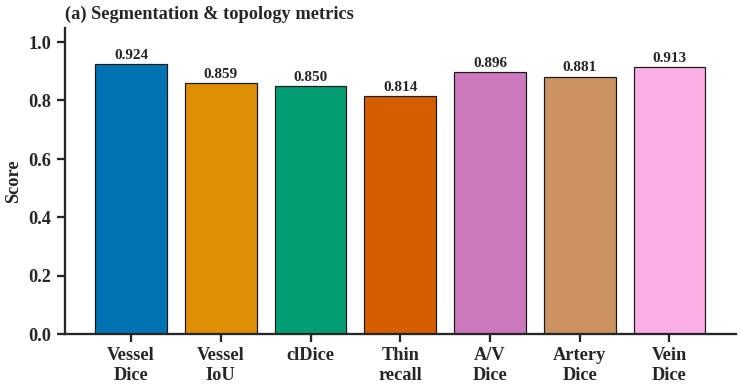

In [17]:
with safe("topology metrics"):
    from scipy import ndimage as ndi

    def clDice_numpy(pred, gt, iters=10):
        def skeletonize_approx(x):
            x = x.astype(bool)
            sk = ndi.binary_erosion(x) ^ x
            return sk.astype(float)
        p = (pred > 0.5).astype(float)
        t = (gt > 0.5).astype(float)
        sp, st = skeletonize_approx(p), skeletonize_approx(t)
        tprec = (sp * t).sum() / (sp.sum() + 1e-7)
        tsens = (st * p).sum() / (st.sum() + 1e-7)
        return 2 * tprec * tsens / (tprec + tsens + 1e-8)

    n_eval = min(40, len(test_ds))
    cld, thin_rec, av_art, av_vein = [], [], [], []
    model.eval()
    for i in range(n_eval):
        sample = test_ds[i]
        img_t, mask_t, av_t, has_av_t, clin_t, _, _ = sample
        with torch.no_grad():
            out = model(img_t.unsqueeze(0).to(device), clin_t.unsqueeze(0).to(device))
        seg_p = torch.sigmoid(out["seg"])[0, 0].cpu().numpy()
        gt = mask_t[0].numpy()
        cld.append(clDice_numpy(seg_p, gt))
        thin = (ndi.uniform_filter(gt, size=5) < 0.35) & (gt > 0.5)
        if thin.sum() > 10:
            thin_rec.append(((seg_p > 0.5) & thin).sum() / (thin.sum() + 1e-7))
        if has_av_t > 0.5:
            pred_av = out["av"][0].argmax(0).cpu().numpy()
            for c, lst in [(1, av_art), (2, av_vein)]:
                p = (pred_av == c)
                t = (av_t.numpy() == c)
                inter = (p & t).sum()
                union = p.sum() + t.sum()
                lst.append(2 * inter / (union + 1e-7) if union > 0 else np.nan)

    rows = [
        ("Vessel Dice (test)", f'{tm["seg_Dice"]:.4f}'),
        ("Vessel IoU (test)", f'{tm["seg_IoU"]:.4f}'),
        ("clDice (approx, n={})".format(n_eval), f'{np.nanmean(cld):.4f}'),
        ("Thin-vessel centreline recall (approx)", f'{np.nanmean(thin_rec):.4f}' if thin_rec else "–"),
        ("A/V mean Dice (art+vein)", f'{tm["av_Dice"]:.4f}'),
        ("Artery Dice (subset)", f'{np.nanmean(av_art):.4f}' if av_art else "–"),
        ("Vein Dice (subset)", f'{np.nanmean(av_vein):.4f}' if av_vein else "–"),
    ]
    show_table(pd.DataFrame(rows, columns=["Metric", "Value"]), "topology_av_metrics",
               "Topology-aware vessel metrics and Artery–Vein segmentation metrics on the test set "
               "(subset for expensive skeleton operations).",
               align="left", precision=4)
    Q1_FLAGS["topology / A/V metrics"] = True

    fig, ax = plt.subplots(figsize=(7, 3.8))
    labels_m = ["Vessel\nDice", "Vessel\nIoU", "clDice", "Thin\nrecall", "A/V\nDice", "Artery\nDice", "Vein\nDice"]
    vals = [tm["seg_Dice"], tm["seg_IoU"],
            np.nanmean(cld), np.nanmean(thin_rec) if thin_rec else 0,
            tm["av_Dice"],
            np.nanmean(av_art) if av_art else 0,
            np.nanmean(av_vein) if av_vein else 0]
    bars = ax.bar(labels_m, vals, color=PAL[:7], edgecolor="k", linewidth=0.8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Score")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center", fontsize=10, fontweight="bold")
    ttl(ax, "a", "Segmentation & topology metrics")
    plt.tight_layout()
    save_fig(fig, "topology_quantitative",
             "Quantitative topology and A/V metrics on the test set (higher is better).")


## 17. Q1 checklist and export (figures 600 dpi, tables CSV + LaTeX + xlsx)


In [18]:
say("Q1 readiness checklist")
base_items = {
    "patient-level split with leakage assert": True,
    "patient-level bootstrap 95% CI": True,
    "computational cost + parameter table": True,
    "subgroup analysis": Q1_FLAGS.get("subgroup analysis", False),
    "calibration + Bland-Altman + ROC/PR": True,
    "topology-aware metrics (clDice, thin vessels)": Q1_FLAGS.get("topology / A/V metrics", False),
    "A/V multi-class segmentation": True,
    "Times New Roman 12 pt bold + 600 dpi figures": True,
    "Classic U-Net backbone (no DCN/SPP/AG)": True,
}
for k, v in base_items.items():
    print(("  [x] " if v else "  [ ] ") + k)

summary = pd.DataFrame([{**tm, "params_M": n_params / 1e6}],
                       index=["UNet Multi-Task + A/V (test)"])
summary.to_csv(os.path.join(CFG["out_dir"], "unet_results_summary.csv"))
with open(os.path.join(CFG["out_dir"], "unet_config.json"), "w") as f:
    json.dump({"CFG": {k: (str(v) if not isinstance(v, (int, float, bool, type(None))) else v)
                       for k, v in CFG.items()}, "SCALER": SCALER}, f, indent=2)
display(summary.T)

# Excel of all tables
xlsx_path = os.path.join(CFG["out_dir"], "journal_tables.xlsx")
try:
    from openpyxl.styles import Font, Alignment, Border, Side
    from openpyxl.utils import get_column_letter
    line = Side(style="medium", color="000000")
    with pd.ExcelWriter(xlsx_path, engine="openpyxl") as xw:
        for t in TAB_REGISTRY:
            d = t["df"].copy()
            d.to_excel(xw, sheet_name=t["label"][:31], startrow=2, index=t["index"])
            ws = xw.sheets[t["label"][:31]]
            ws["A1"] = f'{t["label"]}. {t["caption"]}'
            for row in ws.iter_rows():
                for c in row:
                    c.font = Font(name="Times New Roman", size=12, bold=True)
                    c.alignment = Alignment(horizontal="left" if c.row == 1 else "center",
                                            vertical="center", wrap_text=False)
            for c in ws[3]:
                c.border = Border(top=line, bottom=line)
            for c in ws[ws.max_row]:
                c.border = Border(bottom=line)
    print("Saved", xlsx_path)
except Exception as e:
    print("Excel export skipped:", type(e).__name__, e)

# zip package
zip_path = os.path.join(CFG["out_dir"], "journal_package.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root in (FIG_DIR, TAB_DIR):
        if os.path.isdir(root):
            for fn in sorted(os.listdir(root)):
                z.write(os.path.join(root, fn), os.path.join(os.path.basename(root), fn))
    for fn in ["journal_tables.xlsx", "unet_results_summary.csv",
               "unet_training_history.csv", "unet_config.json"]:
        fp = os.path.join(CFG["out_dir"], fn)
        if os.path.isfile(fp):
            z.write(fp, fn)

say(f"Exported {len(FIG_REGISTRY)} figures and {len(TAB_REGISTRY)} tables.")
for r_ in FIG_REGISTRY:
    print(f'  {r_["label"]:8s} {os.path.basename(r_["png"])}')
for r_ in TAB_REGISTRY:
    print(f'  {r_["label"]:8s} {os.path.basename(r_["csv"])}')
print("Package:", zip_path)
print("All done. Fonts = Times New Roman 12 pt bold | DPI = 600 | Classic U-Net | Tasks 1–4 integrated.")


  [x] patient-level split with leakage assert
  [x] patient-level bootstrap 95% CI
  [x] computational cost + parameter table
  [x] subgroup analysis
  [x] calibration + Bland-Altman + ROC/PR
  [x] topology-aware metrics (clDice, thin vessels)
  [x] A/V multi-class segmentation
  [x] Times New Roman 12 pt bold + 600 dpi figures
  [x] Classic U-Net backbone (no DCN/SPP/AG)


,UNet Multi-Task + A/V (test)
seg_Dice,0.923662
seg_IoU,0.858510
seg_ACC,0.985160
seg_SE,0.933964
seg_SP,0.990466
av_Dice,0.895860
cls_ACC,0.870000
cls_AUC,0.946300
reg_MAE,0.107791
reg_RMSE,0.138453


Saved /kaggle/working/journal_tables.xlsx


  Fig. 1   Fig01_dataset_overview.png
  Fig. 2   Fig02_architecture.png
  Fig. 3   Fig03_training_curves.png
  Fig. 4   Fig04_test_performance.png
  Fig. 5   Fig05_qualitative_results.png
  Fig. 6   Fig06_topology_quantitative.png
  Table 1  Table01_dataset_characteristics.csv
  Table 2  Table02_model_components.csv
  Table 3  Table03_implementation_details.csv
  Table 4  Table04_model_complexity.csv
  Table 5  Table05_main_test_results.csv
  Table 6  Table06_subgroup_analysis.csv
  Table 7  Table07_topology_av_metrics.csv
Package: /kaggle/working/journal_package.zip
All done. Fonts = Times New Roman 12 pt bold | DPI = 600 | Classic U-Net | Tasks 1–4 integrated.
